In [3]:
# load predictions, pool test residuals across seeds
import numpy as np, torch, matplotlib.pyplot as plt, rasterio
from sklearn.ensemble import HistGradientBoostingRegressor
import CGTN_torchdata as D

SLOPE="../data/constructs/sledG_torch_pitedge_pitpit_2010.npz"
BASIN="../data/constructs/basin_mushgraph2010.npz"
LINKS="../data/constructs/pit_basin_links2010.npz"
DEM="../data/rasters/canwell_domainlong_elev2010_5m.tif"

A=D.load_artifacts(SLOPE,BASIN,LINKS); y=A["y"].numpy(); node_rc=A["node_rc"]

pool_y, pool_gtn, pool_gbt, seed0 = [], [], [], {}
for seed in [0,13,42]:
    tr,va,te=[s.numpy() for s in D.make_split(A,seed)]
    ck=torch.load(f"../results/ckpt/GTN_none_s{seed}.pt", map_location="cpu")
    assert np.array_equal(np.sort(ck["split"][2].numpy()), np.sort(te)), "split mismatch"
    gtn=ck["pred"].numpy()
    gbt=HistGradientBoostingRegressor(max_iter=400, learning_rate=0.06, l2_regularization=1.0,
            random_state=seed).fit(A["X_raw"][tr], y[tr]).predict(A["X_raw"])
    pool_y.append(y[te]); pool_gtn.append(gtn[te]-y[te]); pool_gbt.append(gbt[te]-y[te])
    if seed==0: seed0=dict(te=te, r_gtn=gtn[te]-y[te], r_gbt=gbt[te]-y[te])

yt=np.concatenate(pool_y); r_gtn=np.concatenate(pool_gtn); r_gbt=np.concatenate(pool_gbt)
print(f"pooled test nodes {yt.size:,} | GBT MAE {np.abs(r_gbt).mean():.3f} | GTN MAE {np.abs(r_gtn).mean():.3f}")

pooled test nodes 383,337 | GBT MAE 1.303 | GTN MAE 0.969


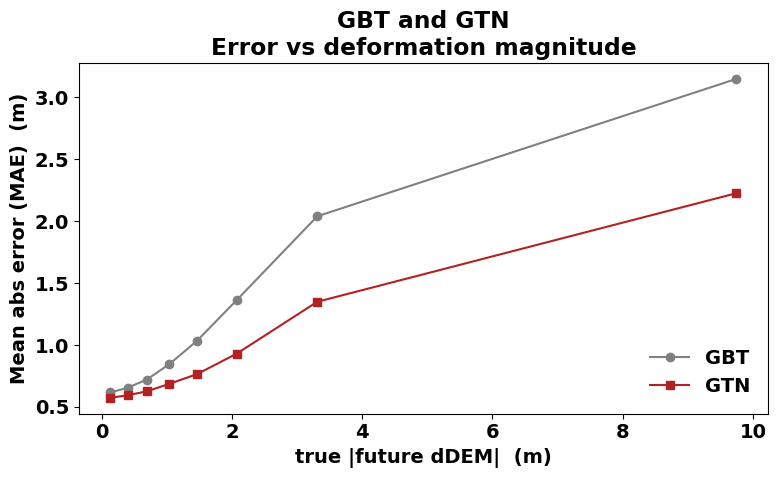

 bin | |y| mean |   n    | GBT MAE | GTN MAE | GTN adv
  0  |   0.13 |  47917 |   0.617 |   0.574 | +0.043
  1  |   0.40 |  47908 |   0.655 |   0.595 | +0.061
  2  |   0.69 |  47911 |   0.721 |   0.626 | +0.095
  3  |   1.03 |  47928 |   0.843 |   0.686 | +0.157
  4  |   1.46 |  47912 |   1.034 |   0.765 | +0.269
  5  |   2.08 |  47926 |   1.365 |   0.932 | +0.433
  6  |   3.31 |  47917 |   2.039 |   1.349 | +0.690
  7  |   9.74 |  47918 |   3.149 |   2.226 | +0.923


In [27]:
# error vs. deformation magnitude

# Set global font size and bold weight
plt.rcParams.update({
    'font.size': 14,
    'font.weight': 'bold',
    'axes.labelweight': 'bold',
    'axes.titleweight': 'bold',
    'figure.titleweight': 'bold'
})

absy=np.abs(yt) # absolute of true y values
edges=np.quantile(absy, np.linspace(0,1,9)); # delimiters of a 9-bin split
edges[-1]+=1e-6 
b=np.clip(np.digitize(absy, edges[1:-1]), 0, 7) # assign a bin # to each absy-value
ctr=[absy[b==k].mean() for k in range(8)] # per-bin mean of values assigned to that bin
mg=[np.abs(r_gtn[b==k]).mean() for k in range(8)] # per-bin mean of gtn residuals
mb=[np.abs(r_gbt[b==k]).mean() for k in range(8)] # per-bin mean of gbt residuals
cnt=[int((b==k).sum()) for k in range(8)]

fig,ax=plt.subplots(figsize=(8,5))
ax.plot(ctr, mb, "o-", color="gray", label="GBT")
ax.plot(ctr, mg, "s-", color="firebrick", label="GTN")
ax.set_xlabel("true |future dDEM|  (m)"); ax.set_ylabel("Mean abs error (MAE)  (m)")
ax.set_title("GBT and GTN\nError vs deformation magnitude"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); 
#plt.savefig("../figures/GTN_error_by_magnitude.png", dpi=200, bbox_inches="tight"); 
plt.show()

print(" bin | |y| mean |   n    | GBT MAE | GTN MAE | GTN adv")
for k in range(8):
    print(f"  {k}  | {ctr[k]:6.2f} | {cnt[k]:6d} | {mb[k]:7.3f} | {mg[k]:7.3f} | {mb[k]-mg[k]:+.3f}")

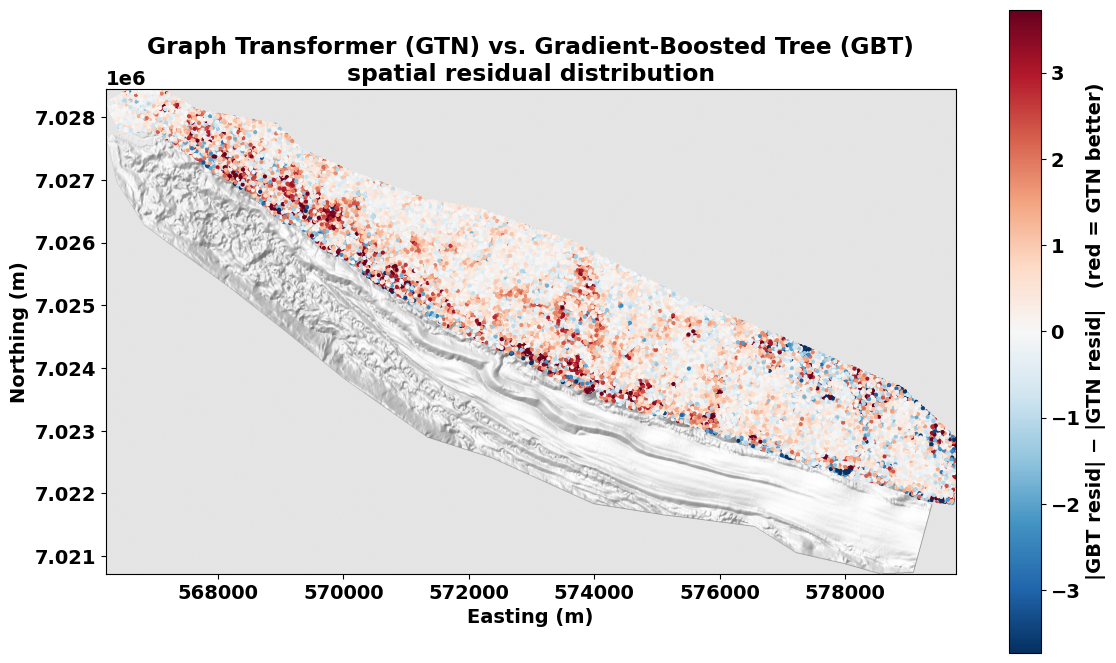

In [23]:
from matplotlib.colors import LightSource
with rasterio.open(DEM) as src:
    dem=src.read(1).astype(float); T=src.transform; H,W=dem.shape
dem[dem<-1e30]=np.nan
extent=(T.c, T.c+W*T.a, T.f+H*T.e, T.f)
hs=LightSource(315,45).hillshade(np.nan_to_num(dem, nan=np.nanmin(dem)), vert_exag=2)

te=seed0["te"]; improve=np.abs(seed0["r_gbt"])-np.abs(seed0["r_gtn"])   # >0 : GTN better
xy=np.c_[T.c+(node_rc[te,1]+0.5)*T.a, T.f+(node_rc[te,0]+0.5)*T.e]
vmax=np.percentile(np.abs(improve), 98)

fig,ax=plt.subplots(figsize=(12,7))
ax.imshow(hs, cmap="gray", extent=extent, origin="upper", alpha=0.6)
sc=ax.scatter(xy[:,0], xy[:,1], c=improve, cmap="RdBu_r", vmin=-vmax, vmax=vmax, s=4)
plt.colorbar(sc, ax=ax, label="|GBT resid| − |GTN resid|   (red = GTN better)")
ax.set_title("Graph Transformer (GTN) vs. Gradient-Boosted Tree (GBT)\nspatial residual distribution")
ax.set_xlabel("Easting (m)"); ax.set_ylabel("Northing (m)")
plt.tight_layout();
#plt.savefig("../figures/fig_spatialimprovement_map.png", dpi=200, bbox_inches="tight"); 
plt.show()

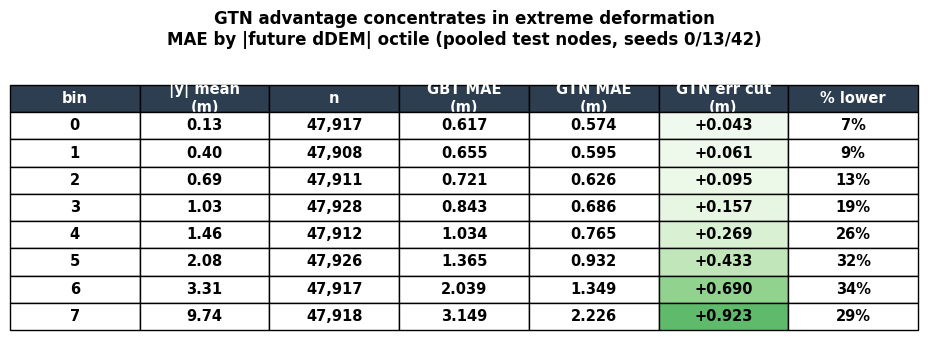

In [19]:
import matplotlib.pyplot as plt, numpy as np

adv = np.array([mb[k]-mg[k] for k in range(8)])
pct = 100*adv/np.array(mb)

rows = [[f"{k}", f"{ctr[k]:.2f}", f"{cnt[k]:,}", f"{mb[k]:.3f}", f"{mg[k]:.3f}",
         f"+{adv[k]:.3f}", f"{pct[k]:.0f}%"] for k in range(8)]
cols = ["bin", "|y| mean\n(m)", "n", "GBT MAE\n(m)", "GTN MAE\n(m)", "GTN err cut\n(m)", "% lower"]

fig, ax = plt.subplots(figsize=(9.5, 3.8)); ax.axis("off")
tbl = ax.table(cellText=rows, colLabels=cols, loc="center", cellLoc="center")
tbl.auto_set_font_size(False); tbl.set_fontsize(10.5); tbl.scale(1, 1.7)

# shade the advantage column to show the gradient
norm = (adv - adv.min()) / (adv.max() - adv.min() + 1e-9)
for k in range(8):
    tbl[k+1, 5].set_facecolor(plt.cm.Greens(0.05 + 0.50*norm[k]))
    tbl[k+1, 5].set_text_props(fontweight="bold")
for j in range(len(cols)):                      # header
    tbl[0, j].set_facecolor("#2c3e50"); tbl[0, j].set_text_props(color="white", fontweight="bold")

ax.set_title("GTN advantage concentrates in extreme deformation\nMAE by |future dDEM| octile (pooled test nodes, seeds 0/13/42)",
             fontsize=12, pad=16)
plt.tight_layout()
#plt.savefig("../figures/GTN_residual_table.png", dpi=220, bbox_inches="tight")
plt.show()